<a href="https://colab.research.google.com/github/Nora0613/website/blob/main/BCI_and_Law_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Research question and hypothesis

Dataset and ethics

Python setup

In [5]:
%pip install -q mne numpy pandas matplotlib scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [8]:
import mne
print ("MNE installed successfully!")
print ("Version:", mne.__version__)

MNE installed successfully!
Version: 1.13.2


In [1]:
import numpy as np
import mne
import sklearn

from sklearn.metrics import balanced_accuracy_score

print("NumPy:", np.__version__)
print("MNE:", mne.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All essential imports work!")

NumPy: 2.1.3
MNE: 1.13.2
Scikit-learn: 1.6.1
All essential imports work!


In [11]:
%pip install --upgrade --force-reinstall scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 18.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 49.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 40.2 MB/s  0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Uninstalling threadpoolctl-3.7.0:
      Successfully uninstalled threadpoolctl-3.7.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
  Attempting uninstall: narwhals
    Found existing installation: narwhals 2.27.1
    Uninstalling narwhals-2.27.1:
      Successfully uninstalled narwhals-2.27.1
  Attempting uninstall: cloudpickle
    Found existing installation: cloudpickle 3.1.2
    Uninstalling cloudpickle-3.1.2:
      Successfully uninstalled cloudpickle-3.1.2
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
    

In [1]:
import sklearn
from sklearn.metrics import balanced_accuracy_score

print("scikit-learn version:", sklearn.__version__)
print("Import successful!")

scikit-learn version: 1.6.1
Import successful!


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


print ("MNE version:", mne.__version__)
print("Python environment is ready")

ModuleNotFoundError: No module named 'mne'

In [3]:
import os
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [4]:
from mne.datasets import eegbci

files = eegbci.load_data(
    subjects=[1],
    runs=[4, 8, 12],
    path="/content/mne_data"
)

print("Files downloaded or located:")

for file in files:
  print(os.path.basename(file))
  print(file)

Files downloaded or located:
S001R04.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R04.edf
S001R08.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R08.edf
S001R12.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R12.edf


In [5]:
raw = mne.io.read_raw_edf(
    files[0],
    preload=True,
    verbose=False
)

mne.datasets.eegbci.standardize(raw)

print(raw)
print("\nSampling frequency:", raw.info["sfreq"], "Hz")
print("Number of channels:", len(raw.ch_names))
print("First 15 channel names:", raw.ch_names[:15])
print("\nAnnotations:")
print(raw.annotations)

<RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

Sampling frequency: 160.0 Hz
Number of channels: 64
First 15 channel names: ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5']

Annotations:
<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>


In [7]:
events, event_id = mne.events_from_annotations(
    raw,
    verbose=False
)
print("Available event labels:")
print(event_id)

print("\nNumber of events:",len(events))

Available event labels:
{'T0': 1, 'T1': 2, 'T2': 3}

Number of events: 30


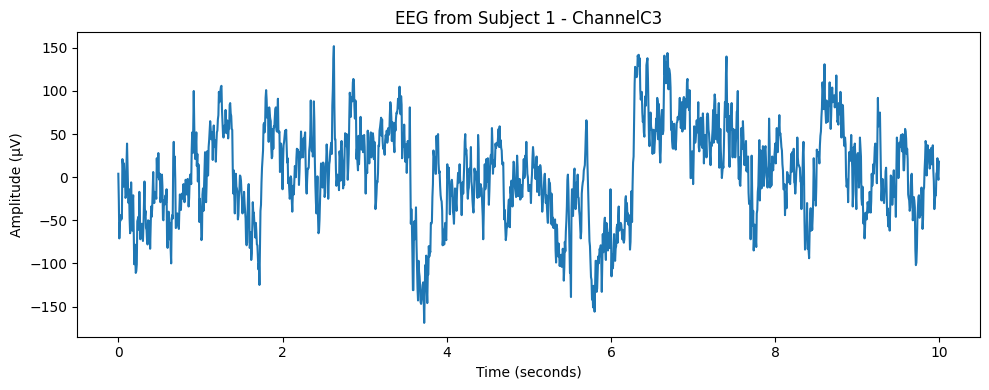

In [9]:
channel = "C3" if "C3" in raw.ch_names else raw.ch_names[0]

signal, times = raw.get_data(
    picks=[channel],
    start=0,
    stop=1600,
    return_times=True
)

plt.figure(figsize=(10, 4))
plt.plot(times, signal[0]*1e6)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title(f"EEG from Subject 1 - Channel{channel}")
plt.tight_layout()
plt.show()

Downloading and Inspection of EEG data

Signal processing

Feature extraction

Model training and testing

Results and graphs

Legal analysis

Limitations and conclusion

References